# A prior for a panel of experts

In this tutorial, we learn one prior for a panel of five experts who do not agree.
Each expert gets a prior of their own.
The experts share a panel value, and each expert has an offset from it.
The result is the **population prior**: the prior of a new expert from the same panel.

We go through three steps:

1. Simulate the answers of five experts.
2. Fit the panel with partial pooling.
3. Check the offsets and the population prior.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import joblib


def _warm() -> None:
    import elicito  # noqa: F401


joblib.Parallel(n_jobs=4)(joblib.delayed(_warm)() for _ in range(4))

import tensorflow as tf

tf.constant(0.0)

<tf.Tensor: shape=(), dtype=float32, numpy=0.0>

## Imports

In [2]:
from functools import partial
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow_probability as tfp

import elicito as el

tfd = tfp.distributions

## The model of one expert

The model is the linear regression of
[Getting started with parametric priors][getting-started-with-parametric-priors].
We write it for one expert.
`elicito` runs it once for each expert.

In [3]:
def X_design(N: int, quantiles: list[float]) -> Any:
    """
    Compute the design matrix

    Parameters
    ----------
    N
        number of observations

    quantiles
        percentiles of the scaled predictor, from 0 to 100

    Returns
    -------
    :
        design matrix with one row per percentile
    """
    X = tf.cast(np.arange(N), tf.float32)
    X_scaled = X / tf.math.reduce_std(X)
    X_sel = tfp.stats.percentile(X_scaled, quantiles)
    design = tf.stack([tf.ones(X_sel.shape), X_sel], -1)
    return design


class ToyModel:
    """
    Generative model of the linear regression
    """

    def __call__(self, prior_samples: Any, design_matrix: Any) -> dict[str, Any]:
        """
        Compute the target quantities from the generative model

        Parameters
        ----------
        prior_samples
            prior samples

        design_matrix
            design matrix

        Returns
        -------
        :
            dictionary with the target quantities
        """
        # linear predictor
        epred = tf.matmul(prior_samples[:, :, :-1], design_matrix, transpose_b=True)

        # data-generating model
        likelihood = tfd.Normal(
            loc=epred, scale=tf.expand_dims(prior_samples[:, :, -1], -1)
        )
        # prior predictive distribution
        ypred = likelihood.sample()

        # outcome at the three selected predictor values
        y_X0, y_X1, y_X2 = (ypred[:, :, 0], ypred[:, :, 1], ypred[:, :, 2])

        return dict(y_X0=y_X0, y_X1=y_X1, y_X2=y_X2)


model = partial(ToyModel(), design_matrix=X_design(N=30, quantiles=[25, 50, 75]))

Each expert states five quantiles of the outcome at three values of the predictor.

In [4]:
parameters = [
    el.parameter(
        name="beta0",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu0"), scale=el.hyper("sigma0", lower=0)),
    ),
    el.parameter(
        name="beta1",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu1"), scale=el.hyper("sigma1", lower=0)),
    ),
    el.parameter(
        name="sigma",
        family=tfd.HalfNormal,
        hyperparams=dict(scale=el.hyper("sigma2", lower=0)),
    ),
]

PROBS = (0.05, 0.25, 0.50, 0.75, 0.95)
targets = [el.quantiles(f"y_X{k}", probs=PROBS) for k in range(3)]

## The panel

We simulate the panel, so we know the truth.
Expert $e$ has the prior $\beta_{j,e} \sim \text{Normal}(\mu_j + \delta_{j,e}, \sigma_j)$.
The offsets $\delta_{j,e}$ have the spread $\tau_j$: the disagreement in the panel.
The disagreement is large for the intercept ($\tau_0 = 3$) and small for the slope ($\tau_1 = 1$).

In [5]:
EXPERTS = (1, 2, 3, 4, 5)
MU = (5.0, 2.0)
SIGMA = (1.0, 1.0)
TAU = (3.0, 1.0)
S = 7.0

rng = np.random.default_rng(2025)
# one row per expert, one column per coefficient
DELTA = rng.normal(loc=0.0, scale=TAU, size=(len(EXPERTS), 2))


def oracle(e: int) -> Any:
    """Return the answers of expert e, simulated from their true prior"""
    d0, d1 = DELTA[e - 1]
    ground_truth = {
        "beta0": tfd.Normal(loc=float(MU[0] + d0), scale=SIGMA[0]),
        "beta1": tfd.Normal(loc=float(MU[1] + d1), scale=SIGMA[1]),
        "sigma": tfd.HalfNormal(scale=S),
    }
    return el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)


experts = {f"expert {e}": oracle(e) for e in EXPERTS}

Five offsets are a small sample.
Their standard deviation is the best estimate of $\tau_j$ that any method can reach from this panel.

In [6]:
DELTA_SD = DELTA.std(axis=0, ddof=1)
print(f"sd of the true offsets: {DELTA_SD[0]:.2f}, {DELTA_SD[1]:.2f}")

sd of the true offsets: 3.89, 0.71


## Fit the panel

`pool=el.partial(over=["mu0", "mu1"])` gives each expert an offset from the panel value of `mu0` and `mu1`.
All experts share the other hyperparameters.
`elicito` estimates the spread of the offsets from the answers.
[`partial`][elicito.specs.partial] explains the settings.

The panel fit is slow: it searches 15 hyperparameters, twice.

In [7]:
eliobj = el.Elicit(
    model,
    targets,
    parameters,
    pool=el.partial(over=["mu0", "mu1"]),
    seeds=(2025, 2026, 2027, 2028, 2029),
    epochs=3000,
    verbose=False,
)

panel = eliobj.fit(experts)
panel

Panel of 5 experts, pool='partial'
tau: mu0=3.7, mu1=0.698

Hyperparameters:
                mu0     sigma0        mu1     sigma1     sigma2
panel          1.63       1.81          2      0.994       6.86
expert 1      -1.21       1.81       1.82      0.994       6.86
expert 2       1.87       1.81       1.75      0.994       6.86
expert 3      -1.32       1.81       2.15      0.994       6.86
expert 4        2.8       1.81       2.09      0.994       6.86
expert 5       6.79       1.81       2.27      0.994       6.86

## Check the fit

Each point compares one answer of one expert with the same quantile of the learned model.
The points lie on the diagonal when the learned priors reproduce the answers.

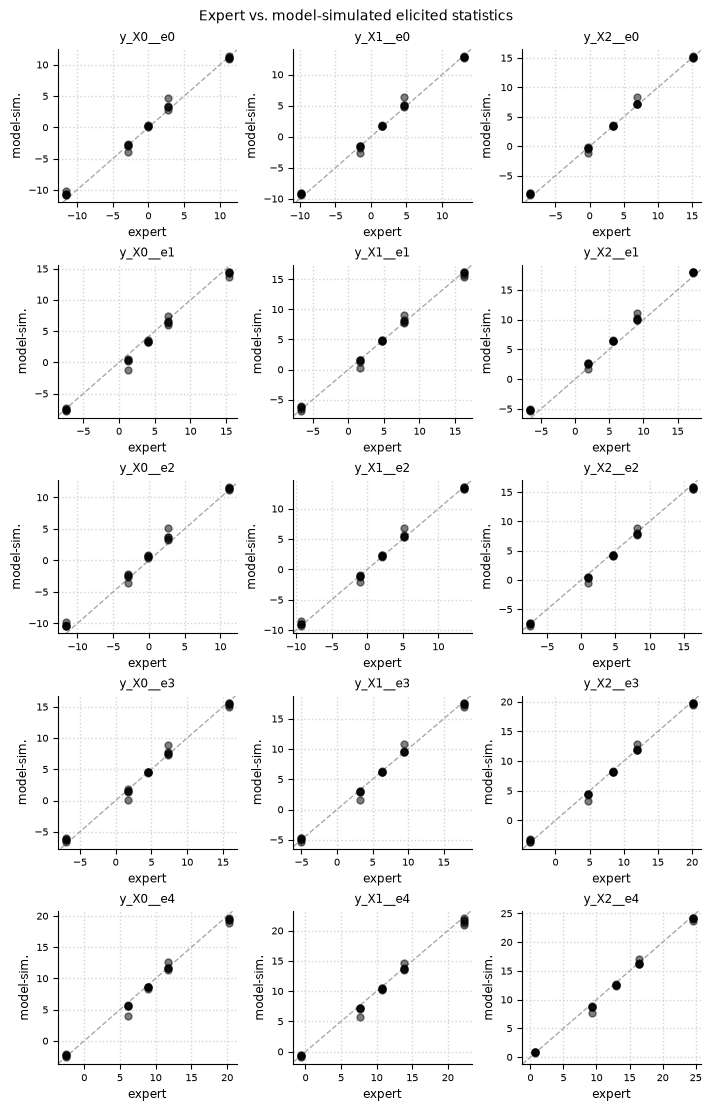

In [8]:
panel.joint.plot.elicits(cols=3, figsize=(7, 11));

The learned spread of the offsets must be near the standard deviation of the true offsets.

In [9]:
for (name, tau), sd in zip(panel.tau.items(), DELTA_SD):
    print(f"{name}: learned tau = {tau:.2f}, sd of the true offsets = {sd:.2f}")

mu0: learned tau = 3.70, sd of the true offsets = 3.89
mu1: learned tau = 0.70, sd of the true offsets = 0.71


The learned offsets must follow the true offsets.
The panel value takes the mean of the offsets, so we centre the truth.

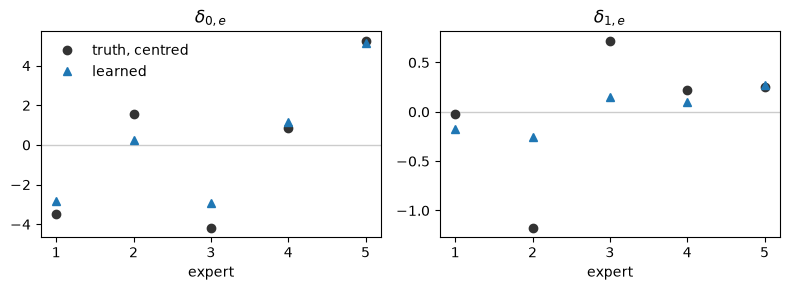

In [10]:
offsets = panel.offsets()
truth = DELTA - DELTA.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True)
for j, (name, ax) in enumerate(zip(["mu0", "mu1"], axes)):
    ax.axhline(0, color="0.8", lw=1)
    ax.plot(EXPERTS, truth[:, j], "o", color="0.2", label="truth, centred")
    ax.plot(EXPERTS, offsets[name].values, "^", label="learned")
    ax.set(title=rf"$\delta_{{{j},e}}$", xlabel="expert", xticks=EXPERTS)
axes[0].legend(frameon=False)
fig.tight_layout();

## The population prior

A new expert from the same panel has the population prior
$\beta_j \sim \text{Normal}\left(\mu_j, \sqrt{\sigma_j^2 + \tau_j^2}\right)$.
The disagreement makes it wider than the prior of one expert.

Five experts cannot show the true population prior.
The dashed line is the population prior that this panel allows.
Its centre is the mean of the five true priors.
Its spread holds the standard deviation of the five true offsets.

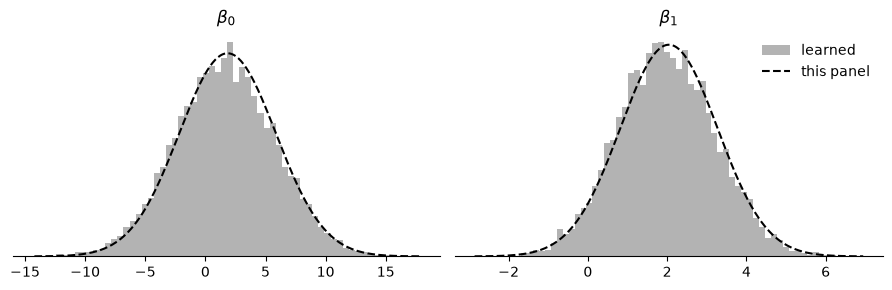

In [11]:
population = panel.population_prior()

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for j, ax in enumerate(axes):
    draws = population[f"beta{j}"].values.ravel()
    centre = float(MU[j] + DELTA[:, j].mean())
    sd = float(np.sqrt(SIGMA[j] ** 2 + DELTA_SD[j] ** 2))
    grid = np.linspace(centre - 4 * sd, centre + 4 * sd, 300, dtype=np.float32)
    ax.hist(draws, bins=60, density=True, color="0.7", label="learned")
    ax.plot(grid, tfd.Normal(centre, sd).prob(grid).numpy(), "k--", label="this panel")
    ax.set(title=rf"$\beta_{j}$", yticks=[])
    ax.spines[["left", "right", "top"]].set_visible(False)
axes[1].legend(frameon=False)
fig.tight_layout();

## Next steps

We learned the priors of five experts and the population prior of their panel.

- [A panel of experts][a-panel-of-experts] explains the offsets, and why `elicito` fits the panel in two stages.
- `pool=None` fits each expert alone. `pool="complete"` learns one prior for all experts. [`Elicit`][elicito.elicit.Elicit] lists all settings.